In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
from scipy import optimize
import random
import operator
import os

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [2]:
plt.rcParams['figure.facecolor'] = 'w'
#plt.rcParams['figure.edgecolor'] = 'k'

In [3]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundCStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
#MdotIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has K-band magnitude
ThreePointSixIndex=17 # Column of imported files that has Spitzer 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has Spitzer 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data

In [4]:
M0StarData[tauIndex]

array([0.0256, 0.0064, 0.0128, ..., 0.0256, 0.0128, 0.0032])

In [6]:
M0_reduced_for_36_minus_80 = clear_rows_with_nAn_for_color (M0StarData, ThreePointSixIndex, EightPointZeroIndex)
M0_color_36_minus_80 = calculate_color (M0_reduced_for_36_minus_80[ThreePointSixIndex],M0_reduced_for_36_minus_80[EightPointZeroIndex])

M1_reduced_for_36_minus_80 = clear_rows_with_nAn_for_color (M1StarData, ThreePointSixIndex, EightPointZeroIndex)
#M1_reduced_for_36_minus_80 = clear_rows_with_color_less_than_value (M1_reduced_for_36_minus_80, ThreePointSixIndex, EightPointZeroIndex,value=-0.25)
print(M1_reduced_for_36_minus_80)
M1_color_36_minus_80 = calculate_color (M1_reduced_for_36_minus_80[ThreePointSixIndex],M1_reduced_for_36_minus_80[EightPointZeroIndex])

C0_reduced_for_36_minus_80 = clear_rows_with_nAn_for_color (C0StarData, ThreePointSixIndex, EightPointZeroIndex)
C0_reduced_for_36_minus_80 = clear_rows_with_color_less_than_value (C0_reduced_for_36_minus_80, ThreePointSixIndex, EightPointZeroIndex,value=0)
C0_color_36_minus_80 = calculate_color (C0_reduced_for_36_minus_80[ThreePointSixIndex],C0_reduced_for_36_minus_80[EightPointZeroIndex])

C1_reduced_for_36_minus_80 = clear_rows_with_nAn_for_color (C1StarData, ThreePointSixIndex, EightPointZeroIndex)
C1_color_36_minus_80 = calculate_color (C1_reduced_for_36_minus_80[ThreePointSixIndex],C1_reduced_for_36_minus_80[EightPointZeroIndex])

M0_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (M0StarData, KIndex, EightPointZeroIndex)
M0_color_K_minus_80 = calculate_color (M0_reduced_for_K_minus_80[KIndex],M0_reduced_for_K_minus_80[EightPointZeroIndex])

M1_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (M1StarData, KIndex, EightPointZeroIndex)
M1_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (M1_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
M1_color_K_minus_80 = calculate_color (M1_reduced_for_K_minus_80[KIndex],M1_reduced_for_K_minus_80[EightPointZeroIndex])

C0_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C0StarData, KIndex, EightPointZeroIndex)
C0_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (C0_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
C0_color_K_minus_80 = calculate_color (C0_reduced_for_K_minus_80[KIndex],C0_reduced_for_K_minus_80[EightPointZeroIndex])

C1_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C1StarData, KIndex, EightPointZeroIndex)
C1_color_K_minus_80 = calculate_color (C1_reduced_for_K_minus_80[KIndex],C1_reduced_for_K_minus_80[EightPointZeroIndex])

[[4.00000000e+00 5.00000000e+00 1.10000000e+01 ... 1.16170000e+04
  1.16200000e+04 1.16540000e+04]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.00000000e-10 3.70000000e-11 7.30000000e-11 ... 2.50000000e-11
  1.60000000e-10 2.80000000e-11]
 ...
 [6.40000000e-03 3.20000000e-03 1.60000000e-03 ... 1.60000000e-03
  6.40000000e-03 3.20000000e-03]
 [3.90971956e+00 2.06941574e+00 3.27460659e+00 ... 3.08690248e+00
  4.78846600e+00 2.04032994e+00]
 [4.59267010e+02 2.35331526e+02 3.95774153e+02 ... 2.96954895e+02
  4.31290067e+02 1.92808002e+02]]


In [5]:
def clear_rows_with_nAn_for_color (RawStarData, band_1_index, band_2_index ):
    band_1_nAn_index = []
    band_2_nAn_index = []
    band_1_data = RawStarData[band_1_index]
    band_2_data = RawStarData[band_2_index]
    band_1_nAn = np.isnan(band_1_data)
    band_2_nAn = np.isnan(band_2_data)
    index_list_1 = np.where(band_1_nAn == True)[0]
    index_list_2 = np.where(band_2_nAn == True)[0]
    full_index_list = np.concatenate((index_list_1, index_list_2))
    full_index_list = np.unique(full_index_list) # Note: This function also *sorts* the array
    working_data = np.transpose(RawStarData)
    reduced_data = np.delete(working_data, full_index_list, 0)
    #print(len(reduced_data))
    return np.transpose(reduced_data)
def clear_rows_with_color_less_than_value (RawStarData, band_1_index, band_2_index,value=0 ):
    band_1_data = RawStarData[band_1_index]
    band_2_data = RawStarData[band_2_index]
    color = band_1_data - band_2_data
    less_than_value = []
    for i in range (0,len(color)):
        if color[i] < value:
            less_than_value.append(i)
    #print(less_than_value)
    full_index_list = np.unique(less_than_value) # Note: This function also *sorts* the array
    working_data = np.transpose(RawStarData)
    reduced_data = np.delete(working_data, full_index_list, 0)
    #print(len(reduced_data))
    return np.transpose(reduced_data)
def calculate_color (band_1, band_2):
    return band_1 - band_2

In [7]:
# Functions to sort a list
def examine_index_third(elem): 
    # Sorting Key. Will sort a list based on the specified index hard coded here.
    return elem[tauIndex]

def sort_star_data_third(DataToSort):
    TransposedArray=np.transpose(DataToSort)
    TempList=TransposedArray.tolist()
    TempList=sorted(TempList,key = operator.itemgetter(1)) # use 2 because we index from 0
    return np.transpose(np.asarray(TempList))

def RangeSelect (DataToTrim, LowerBound, UpperBound ):
    return np.transpose(np.transpose(sort_star_data_third(DataToTrim))[LowerBound:UpperBound])

In [8]:
def chi_sq_fit_2d (data_x, data_y, print_model_results = 0):
    # First, let's look at all of the Fundamental mode data at once.
    # Convert the data into a Pandas DataFrame to use the formulas framework
    # in statsmodels

    # First we need to flatten the data: it's 2D layout is not relevent.
    x = data_x
    y = data_y

    data = pandas.DataFrame({'x': data_x, 'y': data_y})

    # Fit the model
    model = ols("y ~ x ", data).fit()

    # Print the summary
    if print_model_results != 0:
        print(model.summary())

        print("\nRetrieving manually the parameter estimates:")
        print(model._results.params)

        print("\nRetrieving manually the R^2 value:")
        print(model._results.rsquared)
        # Peform analysis of variance on fitted linear model
        anova_results = anova_lm(model)
        print('\nANOVA results')
        print(anova_results)
        
    parameters = model._results.params
    rsquared = model._results.rsquared
    return parameters, rsquared


In [9]:
def plot_logmdot_vs_parameter (mdot, parameter, title='', parameter_label='',save_fig = 0, save_folder = '',testing = 0):
    plot.scatter(parameter,mdot,s=2,label='Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    if testing != 0:
        print('parameter:',parameter)
        print('np.min(parameter):',np.min(parameter))
        print('np.max(parameter):',np.max(parameter))
        print('fit_x:',fit_x)
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    if testing != 0:
        print('fit_y:',fit_x)
    if fit_parameters[0] < 0:
        fit_label = str(fit_parameters[0])[0:7] +'+'+ str(fit_parameters[1])[0:6]+'*('+parameter_label+'); R^2 ='+ str(chisqparams[1])[0:6]
    else:
        fit_label = str(fit_parameters[0])[0:6] +'+'+ str(fit_parameters[1])[0:6]+'*('+parameter_label+'); R^2 ='+ str(chisqparams[1])[0:6]
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_obsv')
    plot.legend()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [10]:
# Replicating the method found in Ribel et al, we will try to fit logMdot = (P0/(Color+P1)) + P2
def hyperbolic_func (C, P0, P1, P2):
    return ((P0/(C+P1)))+P2 
n = 1
# Another function to try fitting.
def hyperbolic_func_ext (C, P0, P1, P2):
    #n = 1
    return ((P0/(C+P1)**(n))+P2)

# Another function to try fitting.
def hyperbolic_func_ext_2 (C, P0, P1, P2, P3):
    return P3*np.log10((P0/(C+P1)))+P2 

# Another function to try fitting.
def hyperbolic_func_ext_3 (C, P0, P1, P2, P3):
    return ((P0/(C+P1)**(P3))+P2)

In [11]:
M0StarData[ThreePointSixIndex]

array([11.55619234, 10.65257755, 11.42795098, ..., 11.57746592,
       11.83975509, 11.0684061 ])

In [12]:
def fit_to_hyperbolic (xdata, ydata, save_fig = 0, plot_title = '', x_label='',y_label='', save_folder = '', flip_axes = 0, z_color_by_data=[],manual_data_bin_tau=0, z_data_to_sort=[]):
    fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func, xdata, ydata)
    fit_left = np.min(xdata)
    fit_right = np.max(xdata)
    #print(fit_left,fit_right)
    fit_data = [fit_left]
    new_elem = fit_left + np.abs((fit_right-fit_left))/100
    while len(fit_data)<100:
        fit_data.append(new_elem)
        new_elem = new_elem + np.abs((fit_right-fit_left))/100
    #print(fit_data)
    fit_curve = hyperbolic_func (fit_data, fit_parameters[0], fit_parameters[1], fit_parameters[2])
    if flip_axes == 0:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_data,fit_curve,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.ylim((np.min(ydata)-0.1), (np.max(ydata)+0.1))
        plot.xlabel(x_label)
        plot.ylabel(y_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
        else:
            plot.show()
    else:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_curve,fit_data,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.xlabel(y_label)
        plot.ylabel(x_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
        else:
            plot.show()
    

In [13]:
def fit_to_hyperbolic_ext (xdata, ydata, save_fig = 0, plot_title = '', x_label='',y_label='', save_folder = '', flip_axes = 0,z_color_by_data=[],manual_data_bin_tau=0, z_data_to_sort=[],in_bounds=[],initial_guess = [],fed_n=1):
    if len (in_bounds) == 0:
        if len(initial_guess) ==0:
            fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_ext, xdata, ydata)
        else:
            fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_ext, xdata, ydata,p0=initial_guess)
    else:
        if len(initial_guess) ==0:
            fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_ext, xdata, ydata,bounds=in_bounds,check_finite=False)
        else:
            fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_ext, xdata, ydata,bounds=in_bounds,check_finite=False,p0=initial_guess)
        
    fit_left = np.min(xdata)
    fit_right = np.max(xdata)
    #print(fit_left,fit_right)
    fit_data = [fit_left]
    new_elem = fit_left + np.abs((fit_right-fit_left))/100
    while len(fit_data)<100:
        fit_data.append(new_elem)
        new_elem = new_elem + np.abs((fit_right-fit_left))/100
    #print(fit_data)
    fit_curve = hyperbolic_func_ext (fit_data, fit_parameters[0], fit_parameters[1], fit_parameters[2])
    if flip_axes == 0:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_data,fit_curve,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters)+', n='+str(fed_n),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.ylim((np.min(ydata)-0.1), (np.max(ydata)+0.1))
        plot.xlabel(x_label)
        plot.ylabel(y_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
        else:
            plot.show()
    else:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_curve,fit_data,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.xlabel(y_label)
        plot.ylabel(x_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
        else:
            plot.show()
    

In [14]:
def fit_to_hyperbolic_ext_2 (xdata, ydata, save_fig = 0, plot_title = '', x_label='',y_label='', save_folder = '', flip_axes = 0,z_color_by_data=[],manual_data_bin_tau=0, z_data_to_sort=[]):
    fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_ext_2, xdata, np.log10(-ydata))
    fit_left = np.min(xdata)
    fit_right = np.max(xdata)
    #print(fit_left,fit_right)
    fit_data = [fit_left]
    new_elem = fit_left + np.abs((fit_right-fit_left))/100
    while len(fit_data)<100:
        fit_data.append(new_elem)
        new_elem = new_elem + np.abs((fit_right-fit_left))/100
    #print(fit_data)
    fit_curve = -10**(hyperbolic_func_ext_2 (fit_data, fit_parameters[0], fit_parameters[1], fit_parameters[2], fit_parameters[3]))
    if flip_axes == 0:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_data,fit_curve,label='fit: a=%5.3f, b=%5.3f, c=%5.3f, d=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.ylim((np.min(ydata)-0.1), (np.max(ydata)+0.1))
        plot.xlabel(x_label)
        plot.ylabel(y_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
        else:
            plot.show()
    else:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_curve,fit_data,label='fit: a=%5.3f, b=%5.3f, c=%5.3f, d=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.xlabel(y_label)
        plot.ylabel(x_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
        else:
            plot.show()
    

In [33]:
def fit_to_hyperbolic_ext_3 (xdata, ydata, save_fig = 0, plot_title = '', x_label='',y_label='', save_folder = '', flip_axes = 0,z_color_by_data=[],manual_data_bin_tau=0, z_data_to_sort=[],in_bounds=[],initial_guess = [],fed_n=1):
    if len (in_bounds) == 0:
        if len(initial_guess) ==0:
            fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_ext_3, xdata, ydata)
        else:
            fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_ext_3, xdata, ydata,p0=initial_guess)
    else:
        if len(initial_guess) ==0:
            fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_ext_3, xdata, ydata,bounds=in_bounds,check_finite=False)
        else:
            fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_ext_3, xdata, ydata,bounds=in_bounds,check_finite=False,p0=initial_guess)
        
    fit_left = np.min(xdata)
    fit_right = np.max(xdata)
    #print(fit_left,fit_right)
    fit_data = [fit_left]
    new_elem = fit_left + np.abs((fit_right-fit_left))/100
    while len(fit_data)<100:
        fit_data.append(new_elem)
        new_elem = new_elem + np.abs((fit_right-fit_left))/100
    #print(fit_data)
    fit_curve = hyperbolic_func_ext_3 (fit_data, fit_parameters[0], fit_parameters[1], fit_parameters[2], fit_parameters[3])
    if flip_axes == 0:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_data,fit_curve,label='fit: a=%5.3f, b=%5.3f, c=%5.3f, n=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.ylim((np.min(ydata)-0.1), (np.max(ydata)+0.1))
        plot.xlabel(x_label)
        plot.ylabel(y_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
        else:
            plot.show()
    else:
        if len(z_color_by_data)>0: 
            plot.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    plot.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            plot.scatter(xdata, ydata, label='Data',s=2)
        plot.plot(fit_curve,fit_data,label='fit: a=%5.3f, b=%5.3f, c=%5.3f, n=%5.3f' % tuple(fit_parameters),color='orange')
        plot.title(plot_title)
        plot.legend()
        plot.xlabel(y_label)
        plot.ylabel(x_label)
        if save_fig !=0:
            plot.savefig(save_folder+'/'+fitting_to_label+'_vs_'+parameter_label)
        else:
            plot.show()
    

sorted_data: [[ 2.95671851e-02  1.24106750e-01  1.76608141e-01 ...  9.66546908e-01
   1.11381936e+00  1.44192253e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.94719579e+00 ... -5.80889310e+00
  -5.73634243e+00 -5.64616580e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


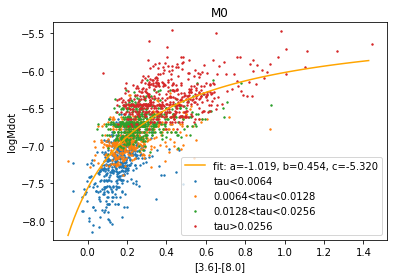

sorted_data: [[ 3.59251987e-02  1.39651683e-01  1.40595359e-01 ...  1.18706184e+00
   1.40201570e+00  1.01512561e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.91076653e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2147
bin_bottom: 536
bin_top: 1072
bin_bottom: 1072
bin_top: 1608
bin_bottom: 1608
bin_top: 2144
bin_bottom: 2144
bin_top: 2680


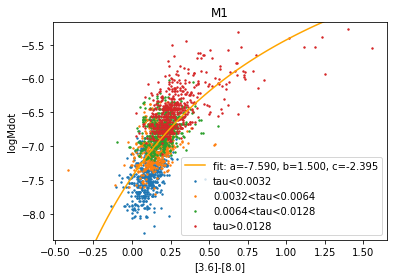

sorted_data: [[ 2.97271066e-01  1.91627249e-01  3.89036054e-01 ...  1.33008982e+00
   1.36402184e+00  1.49495378e+00]
 [-7.34328304e+00 -7.67427626e+00 -7.34328304e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1981
bin_bottom: 495
bin_top: 990
bin_bottom: 990
bin_top: 1485
bin_bottom: 1485
bin_top: 1980
bin_bottom: 1980
bin_top: 2475


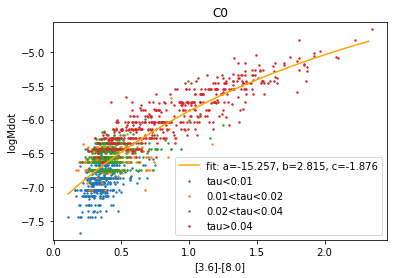

sorted_data: [[ 2.08216888e-01  2.13640021e-01  2.19685482e-01 ...  1.43600287e+00
   1.14102136e+00  2.53293006e+00]
 [-7.43505341e+00 -7.43505341e+00 -7.43505341e+00 ... -5.55155898e+00
  -5.62410965e+00 -4.38674873e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  3.00000000e-01
   3.00000000e-01  4.00000000e-01]]
len(data_to_sort): 771
bin_bottom: 192
bin_top: 384
bin_bottom: 384
bin_top: 576
bin_bottom: 576
bin_top: 768
bin_bottom: 768
bin_top: 960


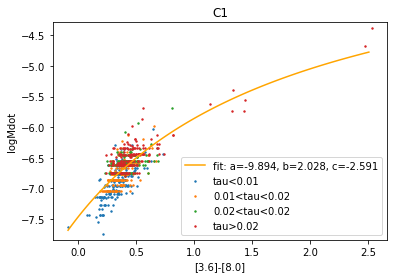

In [16]:
fit_to_hyperbolic(M0_color_36_minus_80,np.log10(M0_reduced_for_36_minus_80[MdotIndex]), plot_title='M0', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_36_minus_80[tauIndex])
fit_to_hyperbolic(M1_color_36_minus_80,np.log10(M1_reduced_for_36_minus_80[MdotIndex]), plot_title='M1', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_36_minus_80[tauIndex])
fit_to_hyperbolic(C0_color_36_minus_80,np.log10(C0_reduced_for_36_minus_80[MdotIndex]), plot_title='C0', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_36_minus_80[tauIndex])
fit_to_hyperbolic(C1_color_36_minus_80,np.log10(C1_reduced_for_36_minus_80[MdotIndex]), plot_title='C1', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=C1_reduced_for_36_minus_80[tauIndex])

sorted_data: [[ 2.95671851e-02  1.24106750e-01  1.76608141e-01 ...  9.66546908e-01
   1.11381936e+00  1.44192253e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.94719579e+00 ... -5.80889310e+00
  -5.73634243e+00 -5.64616580e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


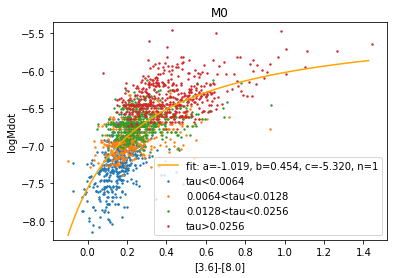

sorted_data: [[ 3.59251987e-02  1.39651683e-01  1.40595359e-01 ...  1.18706184e+00
   1.40201570e+00  1.01512561e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.91076653e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2147
bin_bottom: 536
bin_top: 1072
bin_bottom: 1072
bin_top: 1608
bin_bottom: 1608
bin_top: 2144
bin_bottom: 2144
bin_top: 2680


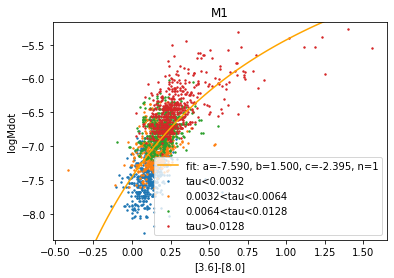

sorted_data: [[ 2.97271066e-01  1.91627249e-01  3.89036054e-01 ...  1.33008982e+00
   1.36402184e+00  1.49495378e+00]
 [-7.34328304e+00 -7.67427626e+00 -7.34328304e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1981
bin_bottom: 495
bin_top: 990
bin_bottom: 990
bin_top: 1485
bin_bottom: 1485
bin_top: 1980
bin_bottom: 1980
bin_top: 2475


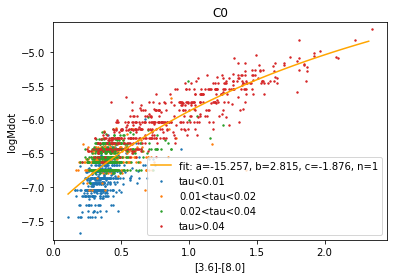

sorted_data: [[ 2.08216888e-01  2.13640021e-01  2.19685482e-01 ...  1.43600287e+00
   1.14102136e+00  2.53293006e+00]
 [-7.43505341e+00 -7.43505341e+00 -7.43505341e+00 ... -5.55155898e+00
  -5.62410965e+00 -4.38674873e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  3.00000000e-01
   3.00000000e-01  4.00000000e-01]]
len(data_to_sort): 771
bin_bottom: 192
bin_top: 384
bin_bottom: 384
bin_top: 576
bin_bottom: 576
bin_top: 768
bin_bottom: 768
bin_top: 960


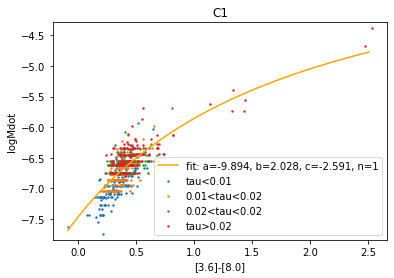

In [17]:
fit_to_hyperbolic_ext(M0_color_36_minus_80,np.log10(M0_reduced_for_36_minus_80[MdotIndex]), plot_title='M0', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_36_minus_80[tauIndex],fed_n=n)
fit_to_hyperbolic_ext(M1_color_36_minus_80,np.log10(M1_reduced_for_36_minus_80[MdotIndex]), plot_title='M1', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_36_minus_80[tauIndex],fed_n=n)
fit_to_hyperbolic_ext(C0_color_36_minus_80,np.log10(C0_reduced_for_36_minus_80[MdotIndex]), plot_title='C0', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_36_minus_80[tauIndex],fed_n=n)
fit_to_hyperbolic_ext(C1_color_36_minus_80,np.log10(C1_reduced_for_36_minus_80[MdotIndex]), plot_title='C1', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=C1_reduced_for_36_minus_80[tauIndex],fed_n=n)

sorted_data: [[ 2.95671851e-02  1.24106750e-01  1.76608141e-01 ...  9.66546908e-01
   1.11381936e+00  1.44192253e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.94719579e+00 ... -5.80889310e+00
  -5.73634243e+00 -5.64616580e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:12: RuntimeWarning: invalid value encountered in log10
  if sys.path[0] == '':


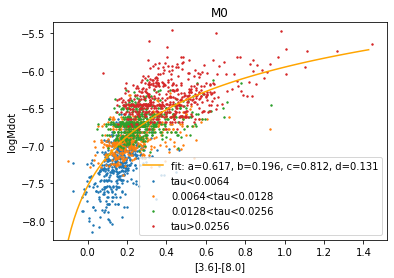

sorted_data: [[ 3.59251987e-02  1.39651683e-01  1.40595359e-01 ...  1.18706184e+00
   1.40201570e+00  1.01512561e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.91076653e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2147
bin_bottom: 536
bin_top: 1072
bin_bottom: 1072
bin_top: 1608
bin_bottom: 1608
bin_top: 2144
bin_bottom: 2144
bin_top: 2680


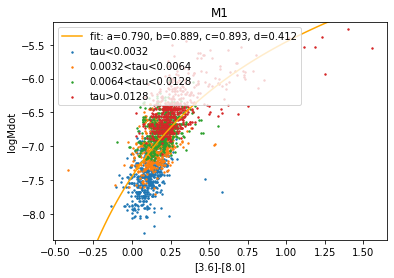

sorted_data: [[ 2.97271066e-01  1.91627249e-01  3.89036054e-01 ...  1.33008982e+00
   1.36402184e+00  1.49495378e+00]
 [-7.34328304e+00 -7.67427626e+00 -7.34328304e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1981
bin_bottom: 495
bin_top: 990
bin_bottom: 990
bin_top: 1485
bin_bottom: 1485
bin_top: 1980
bin_bottom: 1980
bin_top: 2475


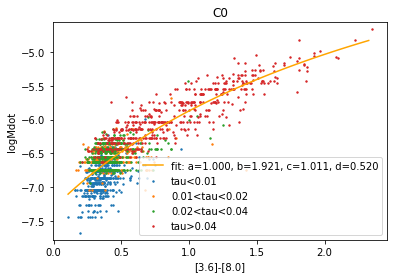

sorted_data: [[ 2.08216888e-01  2.13640021e-01  2.19685482e-01 ...  1.43600287e+00
   1.14102136e+00  2.53293006e+00]
 [-7.43505341e+00 -7.43505341e+00 -7.43505341e+00 ... -5.55155898e+00
  -5.62410965e+00 -4.38674873e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  3.00000000e-01
   3.00000000e-01  4.00000000e-01]]
len(data_to_sort): 771
bin_bottom: 192
bin_top: 384
bin_bottom: 384
bin_top: 576
bin_bottom: 576
bin_top: 768
bin_bottom: 768
bin_top: 960


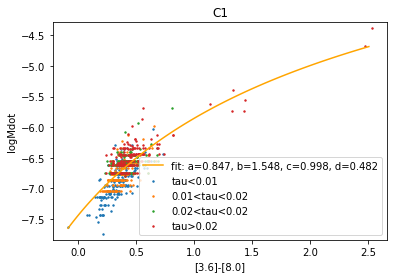

In [18]:
fit_to_hyperbolic_ext_2(M0_color_36_minus_80,np.log10(M0_reduced_for_36_minus_80[MdotIndex]), plot_title='M0', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_36_minus_80[tauIndex])
fit_to_hyperbolic_ext_2(M1_color_36_minus_80,np.log10(M1_reduced_for_36_minus_80[MdotIndex]), plot_title='M1', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_36_minus_80[tauIndex])
fit_to_hyperbolic_ext_2(C0_color_36_minus_80,np.log10(C0_reduced_for_36_minus_80[MdotIndex]), plot_title='C0', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_36_minus_80[tauIndex])
fit_to_hyperbolic_ext_2(C1_color_36_minus_80,np.log10(C1_reduced_for_36_minus_80[MdotIndex]), plot_title='C1', x_label='[3.6]-[8.0]', y_label = 'logMdot', flip_axes = 0,manual_data_bin_tau=4, z_data_to_sort=C1_reduced_for_36_minus_80[tauIndex])

sorted_data: [[ 2.43978498e-01  2.56057062e-01  2.71986068e-01 ...  1.17215776e+00
   1.12617650e+00  1.69074644e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.95265869e+00 ... -5.67419452e+00
  -5.45234577e+00 -5.73634243e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1942
bin_bottom: 485
bin_top: 970
bin_bottom: 970
bin_top: 1455
bin_bottom: 1455
bin_top: 1940
bin_bottom: 1940
bin_top: 2425


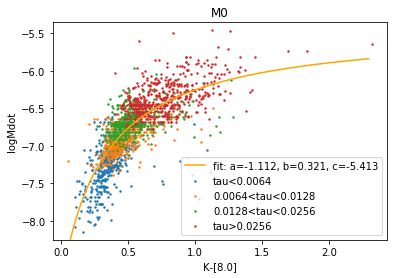

sorted_data: [[ 2.40711174e-01  2.16124151e-01  3.13200174e-01 ...  1.82537331e+00
   2.11823813e+00  1.74923258e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.50786310e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2155
bin_bottom: 538
bin_top: 1076
bin_bottom: 1076
bin_top: 1614
bin_bottom: 1614
bin_top: 2152
bin_bottom: 2152
bin_top: 2690


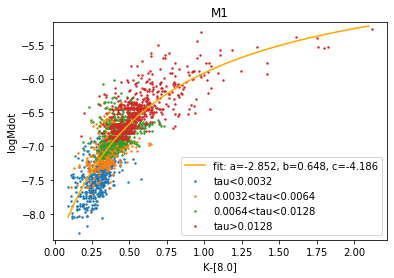

sorted_data: [[ 6.92948434e-01  5.34680061e-01  5.26064180e-01 ...  4.45527777e+00
   4.47330839e+00  4.73984850e+00]
 [-7.34328304e+00 -7.43505341e+00 -7.67427626e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


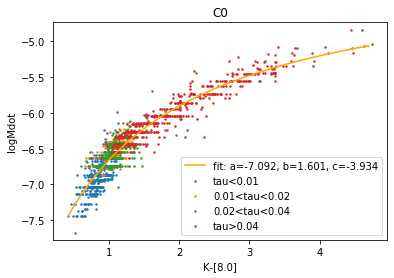

sorted_data: [[ 6.09021517e-01  5.15822729e-01  5.09158021e-01 ...  3.17696459e+00
   2.84701873e+00  4.99729606e+00]
 [-7.43505341e+00 -7.18838108e+00 -7.34328304e+00 ... -5.38674873e+00
  -5.55155898e+00 -4.38674873e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  3.00000000e-01
   3.00000000e-01  4.00000000e-01]]
len(data_to_sort): 779
bin_bottom: 259
bin_top: 518
bin_bottom: 518
bin_top: 777
bin_bottom: 777
bin_top: 1036


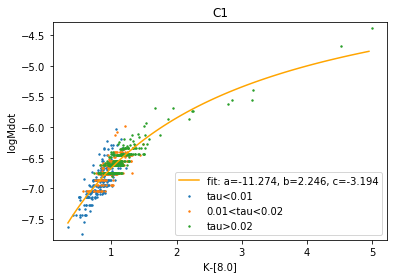

In [19]:
fit_to_hyperbolic(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex])
fit_to_hyperbolic(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex])
fit_to_hyperbolic(C0_color_K_minus_80,np.log10(C0_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_K_minus_80[tauIndex])
fit_to_hyperbolic(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=3, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex])

sorted_data: [[ 2.43978498e-01  2.56057062e-01  2.71986068e-01 ...  1.17215776e+00
   1.12617650e+00  1.69074644e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.95265869e+00 ... -5.67419452e+00
  -5.45234577e+00 -5.73634243e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1942
bin_bottom: 485
bin_top: 970
bin_bottom: 970
bin_top: 1455
bin_bottom: 1455
bin_top: 1940
bin_bottom: 1940
bin_top: 2425


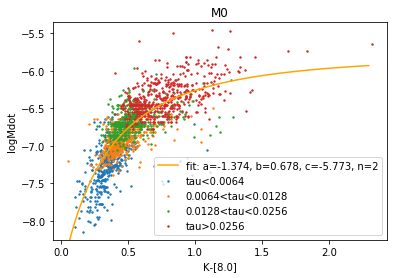

sorted_data: [[ 2.40711174e-01  2.16124151e-01  3.13200174e-01 ...  1.82537331e+00
   2.11823813e+00  1.74923258e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.50786310e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2155
bin_bottom: 538
bin_top: 1076
bin_bottom: 1076
bin_top: 1614
bin_bottom: 1614
bin_top: 2152
bin_bottom: 2152
bin_top: 2690


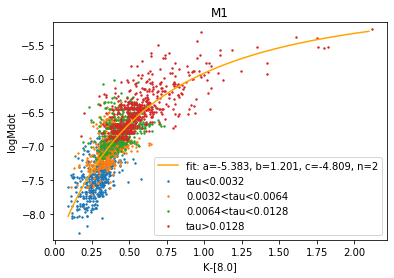

sorted_data: [[ 6.92948434e-01  5.34680061e-01  5.26064180e-01 ...  4.45527777e+00
   4.47330839e+00  4.73984850e+00]
 [-7.34328304e+00 -7.43505341e+00 -7.67427626e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


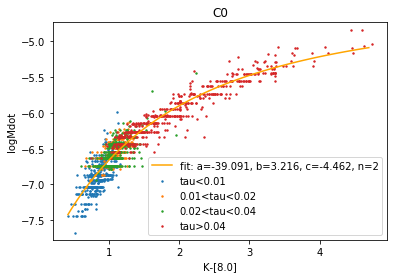

sorted_data: [[ 6.09021517e-01  5.15822729e-01  5.09158021e-01 ...  3.17696459e+00
   2.84701873e+00  4.99729606e+00]
 [-7.43505341e+00 -7.18838108e+00 -7.34328304e+00 ... -5.38674873e+00
  -5.55155898e+00 -4.38674873e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  3.00000000e-01
   3.00000000e-01  4.00000000e-01]]
len(data_to_sort): 779
bin_bottom: 194
bin_top: 388
bin_bottom: 388
bin_top: 582
bin_bottom: 582
bin_top: 776
bin_bottom: 776
bin_top: 970


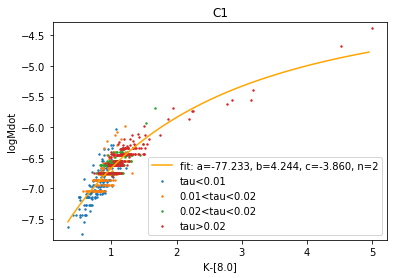

In [20]:
n=2
fit_to_hyperbolic_ext(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-1.112,0.321,-5.413])
fit_to_hyperbolic_ext(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-2.852,0.648,-4.186])
fit_to_hyperbolic_ext(C0_color_K_minus_80,np.log10(C0_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-7.092,1.601,-3.934])
fit_to_hyperbolic_ext(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-11.274,2.246,-3.194])

sorted_data: [[ 2.43978498e-01  2.56057062e-01  2.71986068e-01 ...  1.17215776e+00
   1.12617650e+00  1.69074644e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.95265869e+00 ... -5.67419452e+00
  -5.45234577e+00 -5.73634243e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1942
bin_bottom: 485
bin_top: 970
bin_bottom: 970
bin_top: 1455
bin_bottom: 1455
bin_top: 1940
bin_bottom: 1940
bin_top: 2425


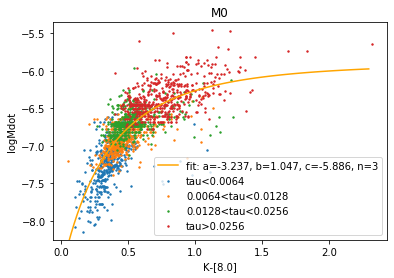

sorted_data: [[ 2.40711174e-01  2.16124151e-01  3.13200174e-01 ...  1.82537331e+00
   2.11823813e+00  1.74923258e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.50786310e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2155
bin_bottom: 538
bin_top: 1076
bin_bottom: 1076
bin_top: 1614
bin_bottom: 1614
bin_top: 2152
bin_bottom: 2152
bin_top: 2690


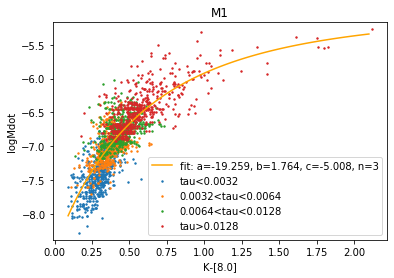

sorted_data: [[ 6.92948434e-01  5.34680061e-01  5.26064180e-01 ...  4.45527777e+00
   4.47330839e+00  4.73984850e+00]
 [-7.34328304e+00 -7.43505341e+00 -7.67427626e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


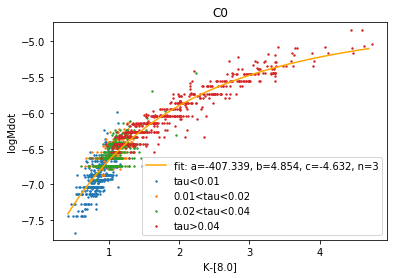

sorted_data: [[ 6.09021517e-01  5.15822729e-01  5.09158021e-01 ...  3.17696459e+00
   2.84701873e+00  4.99729606e+00]
 [-7.43505341e+00 -7.18838108e+00 -7.34328304e+00 ... -5.38674873e+00
  -5.55155898e+00 -4.38674873e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  3.00000000e-01
   3.00000000e-01  4.00000000e-01]]
len(data_to_sort): 779
bin_bottom: 194
bin_top: 388
bin_bottom: 388
bin_top: 582
bin_bottom: 582
bin_top: 776
bin_bottom: 776
bin_top: 970


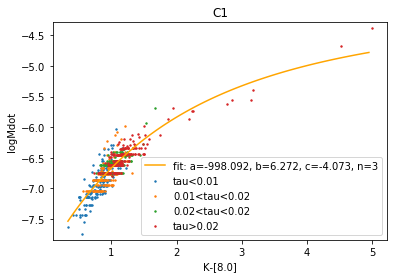

In [21]:
n=3
fit_to_hyperbolic_ext(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-1.112,0.321,-5.413])
fit_to_hyperbolic_ext(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-2.852,0.648,-4.186])
fit_to_hyperbolic_ext(C0_color_K_minus_80,np.log10(C0_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-7.092,1.601,-3.934])
fit_to_hyperbolic_ext(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-11.274,2.246,-3.194])

sorted_data: [[ 2.43978498e-01  2.56057062e-01  2.71986068e-01 ...  1.17215776e+00
   1.12617650e+00  1.69074644e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.95265869e+00 ... -5.67419452e+00
  -5.45234577e+00 -5.73634243e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1942
bin_bottom: 485
bin_top: 970
bin_bottom: 970
bin_top: 1455
bin_bottom: 1455
bin_top: 1940
bin_bottom: 1940
bin_top: 2425


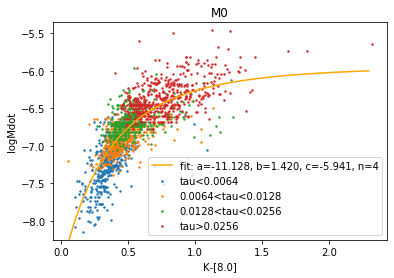

sorted_data: [[ 2.40711174e-01  2.16124151e-01  3.13200174e-01 ...  1.82537331e+00
   2.11823813e+00  1.74923258e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.50786310e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2155
bin_bottom: 538
bin_top: 1076
bin_bottom: 1076
bin_top: 1614
bin_bottom: 1614
bin_top: 2152
bin_bottom: 2152
bin_top: 2690


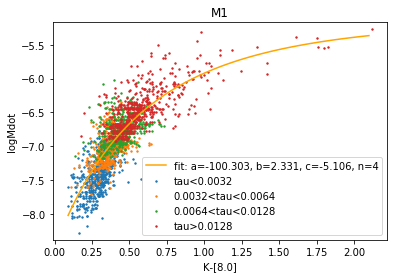

sorted_data: [[ 6.92948434e-01  5.34680061e-01  5.26064180e-01 ...  4.45527777e+00
   4.47330839e+00  4.73984850e+00]
 [-7.34328304e+00 -7.43505341e+00 -7.67427626e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


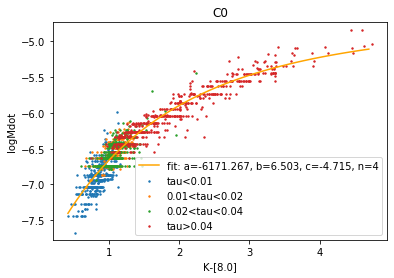

sorted_data: [[ 6.09021517e-01  5.15822729e-01  5.09158021e-01 ...  3.17696459e+00
   2.84701873e+00  4.99729606e+00]
 [-7.43505341e+00 -7.18838108e+00 -7.34328304e+00 ... -5.38674873e+00
  -5.55155898e+00 -4.38674873e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  3.00000000e-01
   3.00000000e-01  4.00000000e-01]]
len(data_to_sort): 779
bin_bottom: 194
bin_top: 388
bin_bottom: 388
bin_top: 582
bin_bottom: 582
bin_top: 776
bin_bottom: 776
bin_top: 970


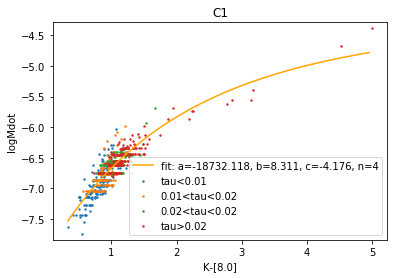

In [22]:
n=4
fit_to_hyperbolic_ext(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-3**n,0.321,-5.413])
fit_to_hyperbolic_ext(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-3**n,0.648,-4.186])
fit_to_hyperbolic_ext(C0_color_K_minus_80,np.log10(C0_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-3**n,1.601,-3.934])
fit_to_hyperbolic_ext(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-3**n,2.246,-3.194])

sorted_data: [[ 2.43978498e-01  2.56057062e-01  2.71986068e-01 ...  1.17215776e+00
   1.12617650e+00  1.69074644e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.95265869e+00 ... -5.67419452e+00
  -5.45234577e+00 -5.73634243e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1942
bin_bottom: 485
bin_top: 970
bin_bottom: 970
bin_top: 1455
bin_bottom: 1455
bin_top: 1940
bin_bottom: 1940
bin_top: 2425


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in power
  


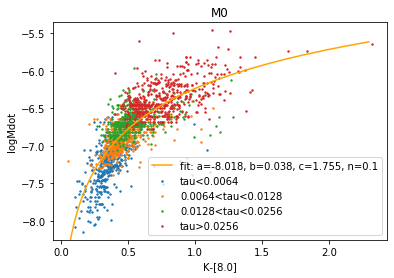

sorted_data: [[ 2.40711174e-01  2.16124151e-01  3.13200174e-01 ...  1.82537331e+00
   2.11823813e+00  1.74923258e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.50786310e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2155
bin_bottom: 538
bin_top: 1076
bin_bottom: 1076
bin_top: 1614
bin_bottom: 1614
bin_top: 2152
bin_bottom: 2152
bin_top: 2690


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in power
  


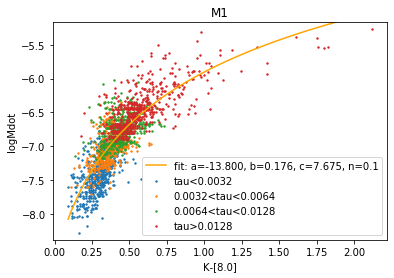

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in power
  


sorted_data: [[ 6.92948434e-01  5.34680061e-01  5.26064180e-01 ...  4.45527777e+00
   4.47330839e+00  4.73984850e+00]
 [-7.34328304e+00 -7.43505341e+00 -7.67427626e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


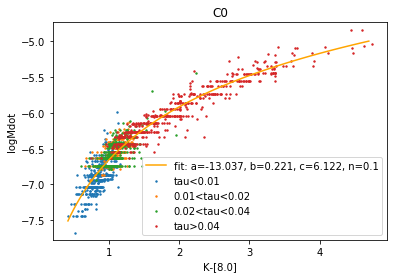

sorted_data: [[ 6.09021517e-01  5.15822729e-01  5.09158021e-01 ...  3.17696459e+00
   2.84701873e+00  4.99729606e+00]
 [-7.43505341e+00 -7.18838108e+00 -7.34328304e+00 ... -5.38674873e+00
  -5.55155898e+00 -4.38674873e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  3.00000000e-01
   3.00000000e-01  4.00000000e-01]]
len(data_to_sort): 779
bin_bottom: 194
bin_top: 388
bin_bottom: 388
bin_top: 582
bin_bottom: 582
bin_top: 776
bin_bottom: 776
bin_top: 970


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in power
  


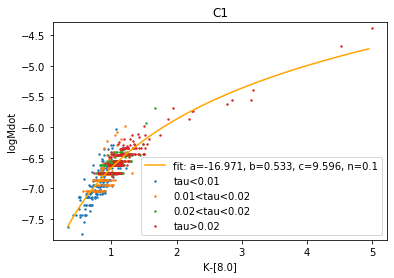

In [23]:
n=0.1
fit_to_hyperbolic_ext(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[1,0.321,-5.413])
fit_to_hyperbolic_ext(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[1,0.648,-4.186])
fit_to_hyperbolic_ext(C0_color_K_minus_80,np.log10(C0_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[1,1.601,-3.934])
fit_to_hyperbolic_ext(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[1,2.246,-3.194])

sorted_data: [[ 2.43978498e-01  2.56057062e-01  2.71986068e-01 ...  1.17215776e+00
   1.12617650e+00  1.69074644e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.95265869e+00 ... -5.67419452e+00
  -5.45234577e+00 -5.73634243e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1942
bin_bottom: 485
bin_top: 970
bin_bottom: 970
bin_top: 1455
bin_bottom: 1455
bin_top: 1940
bin_bottom: 1940
bin_top: 2425


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in power
  


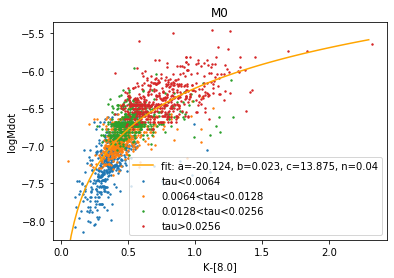

sorted_data: [[ 2.40711174e-01  2.16124151e-01  3.13200174e-01 ...  1.82537331e+00
   2.11823813e+00  1.74923258e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.50786310e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2155
bin_bottom: 538
bin_top: 1076
bin_bottom: 1076
bin_top: 1614
bin_bottom: 1614
bin_top: 2152
bin_bottom: 2152
bin_top: 2690


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in power
  


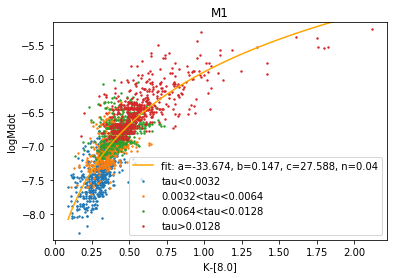

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in power
  


sorted_data: [[ 6.92948434e-01  5.34680061e-01  5.26064180e-01 ...  4.45527777e+00
   4.47330839e+00  4.73984850e+00]
 [-7.34328304e+00 -7.43505341e+00 -7.67427626e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


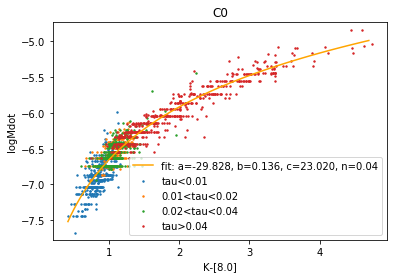

sorted_data: [[ 6.09021517e-01  5.15822729e-01  5.09158021e-01 ...  3.17696459e+00
   2.84701873e+00  4.99729606e+00]
 [-7.43505341e+00 -7.18838108e+00 -7.34328304e+00 ... -5.38674873e+00
  -5.55155898e+00 -4.38674873e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  3.00000000e-01
   3.00000000e-01  4.00000000e-01]]
len(data_to_sort): 779
bin_bottom: 194
bin_top: 388
bin_bottom: 388
bin_top: 582
bin_bottom: 582
bin_top: 776
bin_bottom: 776
bin_top: 970


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:8: RuntimeWarning: invalid value encountered in power
  


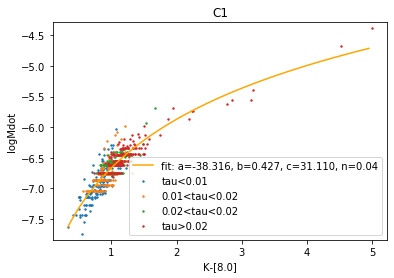

In [43]:
n=0.04
fit_to_hyperbolic_ext(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-1,0.321,-5.413])
fit_to_hyperbolic_ext(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-1,0.648,-4.186])
fit_to_hyperbolic_ext(C0_color_K_minus_80,np.log10(C0_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-1,1.601,-3.934])
fit_to_hyperbolic_ext(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-1,2.246,-3.194])

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in power
  app.launch_new_instance()


sorted_data: [[ 2.43978498e-01  2.56057062e-01  2.71986068e-01 ...  1.17215776e+00
   1.12617650e+00  1.69074644e+00]
 [-8.05789409e+00 -8.03737242e+00 -7.95265869e+00 ... -5.67419452e+00
  -5.45234577e+00 -5.73634243e+00]
 [ 4.00000000e-04  8.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   2.04800000e-01  2.04800000e-01]]
len(data_to_sort): 1942
bin_bottom: 485
bin_top: 970
bin_bottom: 970
bin_top: 1455
bin_bottom: 1455
bin_top: 1940
bin_bottom: 1940
bin_top: 2425


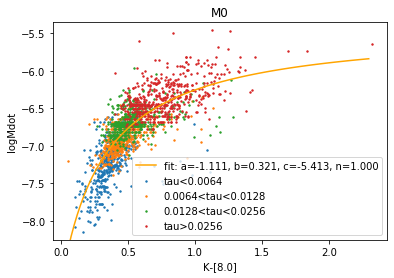

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in power
  app.launch_new_instance()


sorted_data: [[ 2.40711174e-01  2.16124151e-01  3.13200174e-01 ...  1.82537331e+00
   2.11823813e+00  1.74923258e+00]
 [-7.67419452e+00 -8.17818792e+00 -7.50786310e+00 ... -5.52806649e+00
  -5.27050218e+00 -5.40312775e+00]
 [ 4.00000000e-04  4.00000000e-04  8.00000000e-04 ...  2.04800000e-01
   4.09600000e-01  4.09600000e-01]]
len(data_to_sort): 2155
bin_bottom: 538
bin_top: 1076
bin_bottom: 1076
bin_top: 1614
bin_bottom: 1614
bin_top: 2152
bin_bottom: 2152
bin_top: 2690


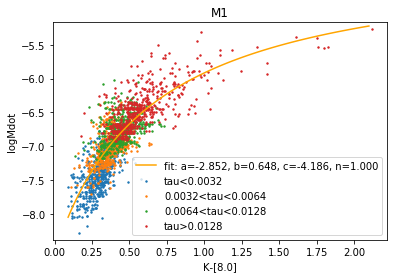

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in power
  app.launch_new_instance()


sorted_data: [[ 6.92948434e-01  5.34680061e-01  5.26064180e-01 ...  4.45527777e+00
   4.47330839e+00  4.73984850e+00]
 [-7.34328304e+00 -7.43505341e+00 -7.67427626e+00 ... -5.08571873e+00
  -5.16035235e+00 -5.04225304e+00]
 [ 1.00000000e-03  1.00000000e-03  1.00000000e-03 ...  6.00000000e-01
   6.00000000e-01  7.00000000e-01]]
len(data_to_sort): 1946
bin_bottom: 486
bin_top: 972
bin_bottom: 972
bin_top: 1458
bin_bottom: 1458
bin_top: 1944
bin_bottom: 1944
bin_top: 2430


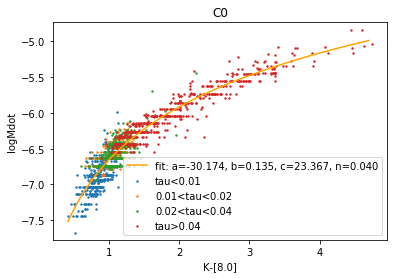

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in power
  app.launch_new_instance()


RuntimeError: Optimal parameters not found: The maximum number of function evaluations is exceeded.

In [38]:

fit_to_hyperbolic_ext_3(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-1.112,0.321,-5.413,0.1],in_bounds=[[-np.inf,-np.inf,-np.inf,0],[0,np.inf,np.inf,1]])
fit_to_hyperbolic_ext_3(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-2.852,0.648,-4.186,0.1],in_bounds=[[-np.inf,-np.inf,-np.inf,0],[0,np.inf,np.inf,1]])
fit_to_hyperbolic_ext_3(C0_color_K_minus_80,np.log10(C0_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-7.092,1.601,-3.934,0.1],in_bounds=[[-np.inf,-np.inf,-np.inf,0],[0,np.inf,np.inf,1]])
fit_to_hyperbolic_ext_3(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex],fed_n=n, initial_guess=[-11.274,2.246,-3.194,0.1],in_bounds=[[-np.inf,-np.inf,-np.inf,0],[0,np.inf,np.inf,1]])

In [ ]:
fit_to_hyperbolic_ext_2(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex])
fit_to_hyperbolic_ext_2(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex])
fit_to_hyperbolic_ext_2(C0_color_K_minus_80,np.log10(C0_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_reduced_for_K_minus_80[tauIndex])
fit_to_hyperbolic_ext_2(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = 'logMdot',manual_data_bin_tau=3, z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex])